# Preprocessing Pipeline for Latin

Under each level 2 or smaller heading, choose one or more cells do run. Each cell is a single step that can be added to the whole pipeline. To skip a step, simply convert the cell to `raw` type with `esc` + `r` keys. By default, all steps are initially skipped.

## Initial Setup

Frequently used Python modules.

In [18]:
import re, os, cltk, requests, spacy, textblob
from pprint import pprint
from termcolor import colored, cprint
import unicodedata
import json

In [2]:
from importlib.metadata import version

print("CLTK version:", version("cltk"))

CLTK version: 2.5.1


### *From URI*

In [3]:
def load_uri(uri: str) -> str:
    response = requests.get(uri, timeout=30)
    response.raise_for_status()
    return response.text

In [4]:
api_url = (
    "https://api.github.com/repos/"
    "PerseusDL/canonical-latinLit/git/trees/master?recursive=1"
)

response = requests.get(api_url, timeout=60)
response.raise_for_status()

files = response.json()["tree"]

matches = [
    item["path"]
    for item in files
    if item["path"].endswith(".xml")
    and "/phi0448/" in item["path"]
    and "lat" in item["path"].lower()
]

print("Matching Latin editions:")
for path in matches:
    print(path)

Matching Latin editions:
data/phi0448/phi001/phi0448.phi001.perseus-lat2.xml
data/phi0448/phi002/phi0448.phi002.perseus-lat2.xml
data/phi0448/phi002/phi0448.phi002.perseus-lat3.xml


In [5]:
def preprocess_latin(text: str) -> str:
    # Normalize Unicode
    text = unicodedata.normalize("NFC", text)

    # Replace Latin ligatures
    text = text.replace("æ", "ae").replace("Æ", "Ae")
    text = text.replace("œ", "oe").replace("Œ", "Oe")

    # Remove editorial annotations in angle brackets
    text = re.sub(r"<[^>]*>", "", text)

    # Remove editorial annotations in square brackets
    text = re.sub(r"\[[^\]]*\]", "", text)

    # Rejoin words split across lines
    text = re.sub(r"(\w)-\s*\n\s*(\w)", r"\1\2", text)

    # Normalize spaces while preserving paragraph boundaries
    text = re.sub(r"[^\S\n]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()

In [6]:
file_path = "data/phi0448/phi001/phi0448.phi001.perseus-lat2.xml"

url = (
    "https://raw.githubusercontent.com/"
    "PerseusDL/canonical-latinLit/master/"
    + file_path
)

response = requests.get(url, timeout=60)
response.raise_for_status()

raw_xml = response.text

print("Downloaded characters:", len(raw_xml))
print(raw_xml[:500])

Downloaded characters: 691979
<?xml version="1.0" encoding="UTF-8"?>
<?xml-model href="https://epidoc.stoa.org/schema/latest/tei-epidoc.rng" schematypens="http://relaxng.org/ns/structure/1.0"?>
<TEI xmlns="http://www.tei-c.org/ns/1.0">
<teiHeader xml:lang="eng">
<fileDesc>
<titleStmt>
<title xml:lang="lat">De bello Gallico</title>
<author>Julius Caesar</author>
<editor>T. Rice Holmes</editor>
<sponsor>Perseus Project, Tufts University</sponsor>
<principal>Gregory Crane</principal>
<respStmt>
<resp>Prepared under the supervis


In [7]:
import xml.etree.ElementTree as ET

root = ET.fromstring(raw_xml)

ns = {"tei": "http://www.tei-c.org/ns/1.0"}

body = root.find(".//tei:text/tei:body", ns)

if body is None:
    raise ValueError("Could not find the TEI text body")

latin_text = " ".join(
    text.strip()
    for text in body.itertext()
    if text.strip()
)

print("Extracted characters:", len(latin_text))
print(latin_text[:1000])

Extracted characters: 376375
COMMENTARIUS PRIMUS Gallia est omnis divisa in partes tres, quarum unam incolunt Belgae, aliam Aquitani, tertiam qui ipsorum lingua Celtae, nostra Galli appellantur. Hi omnes lingua, institutis, legibus inter se differunt. Gallos ab Aquitanis Garumna flumen, a Belgis Matrona et Sequana dividit. Horum omnium fortissimi sunt Belgae, propterea quod a cultu atque humanitate provinciae longissime absunt, minimeque ad eos mercatores saepe commeant atque ea quae ad effeminandos animos pertinent important, proximique sunt Germanis, qui trans Rhenum incolunt, quibuscum continenter bellum gerunt. Qua de causa Helvetii quoque reliquos Gallos virtute praecedunt, quod fere cotidianis proeliis cum Germanis contendunt, cum aut suis finibus eos prohibent aut ipsi in eorum finibus bellum gerunt. [Eorum una pars, quam Gallos obtinere dictum est, initium capit a flumine Rhodano, continetur Garumna flumine, Oceano, finibus Belgarum, attingit etiam ab Sequanis et Helvetiis flum

In [8]:
from collections import Counter

ns_uri = "http://www.tei-c.org/ns/1.0"

divisions = root.findall(".//tei:body//tei:div", ns)

print("Total divisions:", len(divisions))

print("\nDivision types:")
print(Counter(div.get("type") for div in divisions))

print("\nFirst 15 divisions:")
for div in divisions[:15]:
    print({
        "type": div.get("type"),
        "subtype": div.get("subtype"),
        "n": div.get("n"),
        "id": div.get("{http://www.w3.org/XML/1998/namespace}id")
    })

Total divisions: 2563

Division types:
Counter({'textpart': 2562, 'edition': 1})

First 15 divisions:
{'type': 'edition', 'subtype': None, 'n': None, 'id': None}
{'type': 'textpart', 'subtype': 'book', 'n': '1', 'id': None}
{'type': 'textpart', 'subtype': 'chapter', 'n': '1', 'id': None}
{'type': 'textpart', 'subtype': 'section', 'n': '1', 'id': None}
{'type': 'textpart', 'subtype': 'section', 'n': '2', 'id': None}
{'type': 'textpart', 'subtype': 'section', 'n': '3', 'id': None}
{'type': 'textpart', 'subtype': 'section', 'n': '4', 'id': None}
{'type': 'textpart', 'subtype': 'section', 'n': '5', 'id': None}
{'type': 'textpart', 'subtype': 'section', 'n': '6', 'id': None}
{'type': 'textpart', 'subtype': 'section', 'n': '7', 'id': None}
{'type': 'textpart', 'subtype': 'chapter', 'n': '2', 'id': None}
{'type': 'textpart', 'subtype': 'section', 'n': '1', 'id': None}
{'type': 'textpart', 'subtype': 'section', 'n': '2', 'id': None}
{'type': 'textpart', 'subtype': 'section', 'n': '3', 'id': No

In [9]:
import pandas as pd

ns = {"tei": "http://www.tei-c.org/ns/1.0"}

records = []

for book in root.findall(".//tei:div[@subtype='book']", ns):
    book_num = book.get("n")

    for chapter in book.findall("./tei:div[@subtype='chapter']", ns):
        chapter_num = chapter.get("n")

        for section in chapter.findall("./tei:div[@subtype='section']", ns):
            section_num = section.get("n")

            text = " ".join(
                fragment.strip()
                for fragment in section.itertext()
                if fragment.strip()
            )

            if text:
                records.append({
                    "work": "De Bello Gallico",
                    "book": book_num,
                    "chapter": chapter_num,
                    "section": section_num,
                    "text": text
                })

df = pd.DataFrame(records)

print("Total sections:", len(df))
display(df.head())

Total sections: 2150


,work,book,chapter,section,text
0,De Bello Gallico,1,1,1,"Gallia est omnis divisa in partes tres, quarum..."
1,De Bello Gallico,1,1,2,"Hi omnes lingua, institutis, legibus inter se ..."
2,De Bello Gallico,1,1,3,"Horum omnium fortissimi sunt Belgae, propterea..."
3,De Bello Gallico,1,1,4,"proximique sunt Germanis, qui trans Rhenum inc..."
4,De Bello Gallico,1,1,5,"[Eorum una pars, quam Gallos obtinere dictum e..."


In [10]:
df["word_count"] = df["text"].str.split().str.len()

print(df["word_count"].describe())
print("\nLongest sections:")
display(df.nlargest(5, "word_count"))

count    2150.000000
mean       23.860465
std        10.890464
min         3.000000
25%        16.000000
50%        22.000000
75%        30.000000
max       106.000000
Name: word_count, dtype: float64

Longest sections:


,work,book,chapter,section,text,word_count
422,De Bello Gallico,2,25,1,Caesar ab X. legionis cohortatione ad dextrum ...,106
105,De Bello Gallico,1,20,5,Haec cum pluribus verbis flens a Caesare peter...,79
140,De Bello Gallico,1,28,3,"Helvetios, Tulingos, Latobrigos in fines suos,...",71
388,De Bello Gallico,2,17,4,Adiuvabat etiam eorum consilium qui rem defere...,71
970,De Bello Gallico,5,28,3,Lucius Aurunculeius compluresque tribuni milit...,70


In [11]:
from transformers import AutoTokenizer

MODEL_NAME = "latincy/latin-bert"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=False,
    trust_remote_code=True
)

df["token_count"] = df["text"].apply(
    lambda text: len(
        tokenizer.encode(text, add_special_tokens=True)
    )
)

print(df["token_count"].describe())

print("\nSections exceeding 512 tokens:")
print((df["token_count"] > 512).sum())

Could not reach the Hub ([WinError 10054] An existing connection was forcibly closed by the remote host). Using cached commit hash for 'latincy/latin-bert'.


count    2150.000000
mean       37.322791
std        16.280292
min         8.000000
25%        25.000000
50%        35.000000
75%        46.000000
max       160.000000
Name: token_count, dtype: float64

Sections exceeding 512 tokens:
0


In [12]:
from pathlib import Path

output_dir = Path("../../SentimentAnalysisLatin/data/raw")
output_dir.mkdir(parents=True, exist_ok=True)

df["cts_urn"] = df.apply(
    lambda row: (
        "urn:cts:latinLit:phi0448.phi001.perseus-lat2:"
        f"{row['book']}.{row['chapter']}.{row['section']}"
    ),
    axis=1
)

df.to_csv(
    output_dir / "de_bello_gallico_sections.csv",
    index=False,
    encoding="utf-8"
)

print(f"Saved {len(df)} sections.")

Saved 2150 sections.


In [34]:
MODEL_NAME = "qwen2.5:7b"
OLLAMA_URL = "http://localhost:11434/api/chat"

SYSTEM_PROMPT = """
You are an expert in Classical Latin and literary sentiment analysis.

Analyze the original Latin passage directly, without translating it.

Your task is to classify AUTHORIAL SENTIMENT:
the attitude conveyed by the author toward the events, people,
or circumstances being described.

Labels:
- positive: The author conveys approval, admiration, satisfaction,
  optimism, triumph, or a favorable evaluation.
- neutral: The author conveys no clearly discernible positive
  or negative evaluation.
- negative: The author conveys disapproval, hostility, concern,
  disappointment, criticism, or an unfavorable evaluation.

Important:
- Consider implicit evaluations and narrative framing.
- Military victory can be positive when presented favorably.
- Military defeat can be negative when presented unfavorably.
- Do not automatically equate violence or suffering with
  negative authorial sentiment.
- Distinguish the author's attitude from characters' emotions.
- Do not substitute modern moral judgments for the author's perspective.
- If the author's attitude cannot be determined, choose neutral.

Return only JSON:
{
  "sentiment": "negative|neutral|positive",
  "confidence": "low|medium|high",
  "reason": "Brief explanation identifying evidence of authorial attitude"
}
"""

def label_latin(text):
    response = requests.post(
        OLLAMA_URL,
        json={
            "model": MODEL_NAME,
            "stream": False,
            "format": "json",
            "options": {
                "temperature": 0,
                "num_ctx": 4096
            },
            "messages": [
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": text}
            ]
        },
        timeout=180
    )

    response.raise_for_status()

    result = json.loads(response.json()["message"]["content"])

    if result["sentiment"] not in {"negative", "neutral", "positive"}:
        raise ValueError(f"Invalid sentiment: {result}")

    return result

In [39]:
OUTPUT_PATH = Path("../../SentimentAnalysisLatin/data/labeled/caesar_authorial_sentiment_v2.csv")
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

label_map = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

# Resume existing progress, or initialize the dataset
if OUTPUT_PATH.exists():
    labeled_df = pd.read_csv(OUTPUT_PATH)
else:
    labeled_df = df.copy()

    labeled_df["sentiment"] = None
    labeled_df["confidence"] = None
    labeled_df["reason"] = None
    labeled_df["label"] = None
    labeled_df["teacher_model"] = MODEL_NAME
    labeled_df["prompt_version"] = "latin_sentiment_v2"

# Label each passage
for i in range(len(labeled_df)):

    # Skip already labeled passages
    if pd.notna(labeled_df.at[i, "sentiment"]):
        continue

    try:
        result = label_latin(labeled_df.at[i, "text"])

        labeled_df.at[i, "sentiment"] = result["sentiment"]
        labeled_df.at[i, "confidence"] = result["confidence"]
        labeled_df.at[i, "reason"] = result["reason"]
        labeled_df.at[i, "label"] = label_map[result["sentiment"]]

        if (i + 1) % 25 == 0:
            labeled_df.to_csv(OUTPUT_PATH, index=False)
            print(f"Processed {i + 1}/{len(labeled_df)}")

    except Exception as e:
        print(f"Error at section {i}: {e}")
        break

# Save remaining results
labeled_df.to_csv(OUTPUT_PATH, index=False)

print("\nLabeling stopped or completed.")
print("Labeled:", labeled_df["sentiment"].notna().sum())
print("Total:", len(labeled_df))

Processed 25/2150
Processed 50/2150
Processed 75/2150
Processed 100/2150
Processed 125/2150
Processed 150/2150
Processed 175/2150
Processed 200/2150
Processed 225/2150
Processed 250/2150
Processed 275/2150
Processed 300/2150
Processed 325/2150
Processed 350/2150
Processed 375/2150
Processed 400/2150
Processed 425/2150
Processed 450/2150
Processed 475/2150
Processed 500/2150
Processed 525/2150
Processed 550/2150
Processed 575/2150
Processed 600/2150
Processed 625/2150
Processed 650/2150
Processed 675/2150
Processed 700/2150
Processed 725/2150
Processed 750/2150
Processed 775/2150
Processed 800/2150
Processed 825/2150
Processed 850/2150
Processed 875/2150
Processed 900/2150
Processed 925/2150
Processed 950/2150
Processed 975/2150
Processed 1000/2150
Processed 1025/2150
Processed 1050/2150
Processed 1075/2150
Processed 1100/2150
Processed 1125/2150
Processed 1150/2150
Processed 1175/2150
Processed 1200/2150
Processed 1225/2150
Processed 1250/2150
Processed 1275/2150
Processed 1300/2150
Pr

In [43]:
# Verify all passages were labeled
print("Total passages:", len(labeled_df))
print("Labeled passages:", labeled_df["sentiment"].notna().sum())
print("Missing labels:", labeled_df["sentiment"].isna().sum())

# Sentiment distribution
print("\nSentiment distribution:")
print(labeled_df["sentiment"].value_counts())

print("\nSentiment percentages:")
print(
    labeled_df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Confidence distribution
print("\nConfidence distribution:")
print(pd.crosstab(
    labeled_df["sentiment"],
    labeled_df["confidence"]
))

Total passages: 2150
Labeled passages: 2150
Missing labels: 0

Sentiment distribution:
sentiment
neutral     1276
negative     732
positive     142
Name: count, dtype: int64

Sentiment percentages:
sentiment
neutral     59.35
negative    34.05
positive     6.60
Name: proportion, dtype: float64

Confidence distribution:
confidence  high  low  medium
sentiment                    
negative     722    0      10
neutral     1225   16      35
positive     141    0       1


In [44]:
from pathlib import Path

review_df = v2_df.copy()

review_df["v1_sentiment"] = v1_df["sentiment"]
review_df["v2_sentiment"] = v2_df["sentiment"]

review_df = review_df[
    review_df["v1_sentiment"] != review_df["v2_sentiment"]
].copy()

review_df["change"] = (
    review_df["v1_sentiment"]
    + " → "
    + review_df["v2_sentiment"]
)

review_path = Path(
    "../../SentimentAnalysisLatin/data/labeled/"
    "caesar_v1_v2_disagreements.csv"
)

review_df.to_csv(review_path, index=False)

print("Saved", len(review_df), "disagreements")
print(review_df["change"].value_counts())

Saved 405 disagreements
change
negative → neutral     249
neutral → positive      89
neutral → negative      38
negative → positive     27
positive → negative      1
positive → neutral       1
Name: count, dtype: int64


In [48]:
import requests
import pandas as pd

AUTHORS = {
    "Cicero": "phi0474",
    "Seneca": "phi1017"
}

API_BASE = (
    "https://api.github.com/repos/"
    "PerseusDL/canonical-latinLit/contents/data"
)

records = []

for author, textgroup in AUTHORS.items():
    url = f"{API_BASE}/{textgroup}"

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    for item in response.json():
        if item["type"] == "dir":
            records.append({
                "author": author,
                "work_id": item["name"],
                "directory_url": item["html_url"]
            })

works_df = pd.DataFrame(records)

print("Works found:", len(works_df))
display(works_df)

Works found: 74


,author,work_id,directory_url
0,Cicero,phi001,https://github.com/PerseusDL/canonical-latinLi...
1,Cicero,phi002,https://github.com/PerseusDL/canonical-latinLi...
2,Cicero,phi003,https://github.com/PerseusDL/canonical-latinLi...
3,Cicero,phi004,https://github.com/PerseusDL/canonical-latinLi...
4,Cicero,phi005,https://github.com/PerseusDL/canonical-latinLi...
...,...,...,...
69,Seneca,phi010,https://github.com/PerseusDL/canonical-latinLi...
70,Seneca,phi011,https://github.com/PerseusDL/canonical-latinLi...
71,Seneca,phi013,https://github.com/PerseusDL/canonical-latinLi...
72,Seneca,phi014,https://github.com/PerseusDL/canonical-latinLi...


In [49]:
import requests
import xml.etree.ElementTree as ET
import pandas as pd
from concurrent.futures import ThreadPoolExecutor

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "PerseusDL/canonical-latinLit/master/data"
)

TEXTGROUPS = {
    "Cicero": "phi0474",
    "Seneca": "phi1017"
}

def get_work_metadata(row):
    author = row["author"]
    work_id = row["work_id"]
    textgroup = TEXTGROUPS[author]

    url = f"{BASE_URL}/{textgroup}/{work_id}/__cts__.xml"

    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()

        root = ET.fromstring(response.content)

        titles = [
            " ".join(element.itertext()).strip()
            for element in root.iter()
            if element.tag.split("}")[-1] == "title"
        ]

        return {
            "author": author,
            "work_id": work_id,
            "title": " | ".join(dict.fromkeys(titles)),
            "metadata_url": url
        }

    except Exception as e:
        return {
            "author": author,
            "work_id": work_id,
            "title": f"ERROR: {e}",
            "metadata_url": url
        }

with ThreadPoolExecutor(max_workers=8) as executor:
    metadata = list(
        executor.map(
            get_work_metadata,
            works_df.to_dict("records")
        )
    )

metadata_df = pd.DataFrame(metadata)

display(
    metadata_df[
        ["author", "work_id", "title"]
    ].to_string(index=False)
)

'author work_id                                        title\nCicero  phi001                              Pro P. Quinctio\nCicero  phi002                        Pro S. Roscio Amerino\nCicero  phi003                        Pro Q. Roscio Comoedo\nCicero  phi004                    Divinatio in Q. Caecilium\nCicero  phi005                                 In C. Verrem\nCicero  phi006                                Pro M. Tullio\nCicero  phi007                                  Pro Fonteio\nCicero  phi008                               Pro A. Caecina\nCicero  phi009            De Imperio Cn. Pompei Ad Quirites\nCicero  phi010                              Pro A. Cluentio\nCicero  phi011                              De Lege Agraria\nCicero  phi012 Pro C. Rabirio Perduellionis Reo Ad Quirites\nCicero  phi013                                 In Catilinam\nCicero  phi014                                Pro L. Murena\nCicero  phi015                                 Pro P. Sulla\nCicero  phi016         

In [50]:
keywords = (
    "epist|attic|familia|lucil|letter"
)

letter_works = metadata_df[
    metadata_df["title"].str.contains(
        keywords,
        case=False,
        na=False
    )
]

display(letter_works[["author", "work_id", "title"]])

,author,work_id,title
55,Cicero,phi056,Letters to his Friends
56,Cicero,phi057,Letters to Atticus
57,Cicero,phi058,Letters to his brother Quintus
58,Cicero,phi059,Letters to Brutus
73,Seneca,phi015,Epistulae


In [51]:
import requests
import pandas as pd

API_BASE = (
    "https://api.github.com/repos/"
    "PerseusDL/canonical-latinLit/contents/data"
)

TARGET_WORKS = [
    ("Cicero", "phi0474", "phi056", "Letters to Friends"),
    ("Cicero", "phi0474", "phi057", "Letters to Atticus"),
    ("Seneca", "phi1017", "phi015", "Epistulae Morales")
]

files = []

for author, textgroup, work_id, title in TARGET_WORKS:
    url = f"{API_BASE}/{textgroup}/{work_id}"

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    for item in response.json():
        if item["name"].endswith(".xml") and item["name"] != "__cts__.xml":
            files.append({
                "author": author,
                "work": title,
                "work_id": work_id,
                "filename": item["name"],
                "download_url": item["download_url"]
            })

files_df = pd.DataFrame(files)

display(files_df)

,author,work,work_id,filename,download_url
0,Cicero,Letters to Friends,phi056,phi0474.phi056.perseus-eng1.xml,https://raw.githubusercontent.com/PerseusDL/ca...
1,Cicero,Letters to Friends,phi056,phi0474.phi056.perseus-lat2.xml,https://raw.githubusercontent.com/PerseusDL/ca...
2,Cicero,Letters to Atticus,phi057,phi0474.phi057.perseus-eng1.xml,https://raw.githubusercontent.com/PerseusDL/ca...
3,Cicero,Letters to Atticus,phi057,phi0474.phi057.perseus-lat2.xml,https://raw.githubusercontent.com/PerseusDL/ca...
4,Seneca,Epistulae Morales,phi015,phi1017.phi015.perseus-lat2.xml,https://raw.githubusercontent.com/PerseusDL/ca...


In [52]:
import requests
import xml.etree.ElementTree as ET
from collections import Counter

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "PerseusDL/canonical-latinLit/master/data"
)

TARGETS = {
    "cicero_friends": {
        "author": "Cicero",
        "work": "Letters to Friends",
        "textgroup": "phi0474",
        "work_id": "phi056",
    },
    "cicero_atticus": {
        "author": "Cicero",
        "work": "Letters to Atticus",
        "textgroup": "phi0474",
        "work_id": "phi057",
    },
    "seneca_letters": {
        "author": "Seneca",
        "work": "Epistulae Morales",
        "textgroup": "phi1017",
        "work_id": "phi015",
    },
}

xml_roots = {}

def local_name(tag):
    return tag.split("}")[-1]

for key, info in TARGETS.items():
    textgroup = info["textgroup"]
    work_id = info["work_id"]

    filename = f"{textgroup}.{work_id}.perseus-lat2.xml"
    url = f"{BASE_URL}/{textgroup}/{work_id}/{filename}"

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    root = ET.fromstring(response.content)
    xml_roots[key] = root

    print(f"\n{'=' * 55}")
    print(f"{info['author']} — {info['work']}")
    print(f"Downloaded: {len(response.content):,} bytes")

    # Count structural elements
    counts = Counter(
        local_name(element.tag)
        for element in root.iter()
    )

    for tag in ["div", "p", "l", "head", "milestone"]:
        print(f"{tag}: {counts[tag]}")

    # Inspect div hierarchy
    divs = [
        element for element in root.iter()
        if local_name(element.tag) == "div"
    ]

    print("\nFirst 8 divisions:")
    for div in divs[:8]:
        print({
            "type": div.get("type"),
            "subtype": div.get("subtype"),
            "n": div.get("n"),
        })

    # Show first 3 paragraphs
    paragraphs = [
        element for element in root.iter()
        if local_name(element.tag) == "p"
    ]

    print("\nSample paragraphs:")
    for paragraph in paragraphs[:3]:
        text = " ".join(" ".join(paragraph.itertext()).split())
        print(text[:350], "\n")


Cicero — Letters to Friends
Downloaded: 1,124,134 bytes
div: 1792
p: 1394
l: 41
head: 16
milestone: 0

First 8 divisions:
{'type': 'edition', 'subtype': None, 'n': 'urn:cts:latinLit:phi0474.phi056.perseus-lat2'}
{'type': 'textpart', 'subtype': 'book', 'n': '1'}
{'type': 'textpart', 'subtype': 'letter', 'n': '1'}
{'type': 'textpart', 'subtype': 'section', 'n': '1'}
{'type': 'textpart', 'subtype': 'section', 'n': '2'}
{'type': 'textpart', 'subtype': 'section', 'n': '3'}
{'type': 'textpart', 'subtype': 'section', 'n': '4'}
{'type': 'textpart', 'subtype': 'letter', 'n': '2'}

Sample paragraphs:
OCR cleanup 

This pointer pattern extracts book and letter and section. 

This pointer pattern extracts book and letter. 


Cicero — Letters to Atticus
Downloaded: 1,327,999 bytes
div: 1957
p: 1620
l: 62
head: 0
milestone: 400

First 8 divisions:
{'type': 'edition', 'subtype': None, 'n': 'urn:cts:latinLit:phi0474.phi057.perseus-lat2'}
{'type': 'textpart', 'subtype': 'book', 'n': '1'}
{'type': 'tex

In [53]:
import pandas as pd
import re

def clean_latin(text):
    return re.sub(r"\s+", " ", text).strip()

def extract_letter_sections(root, info):
    records = []

    ns = {"tei": "http://www.tei-c.org/ns/1.0"}

    for book in root.findall(
        ".//tei:div[@subtype='book']", ns
    ):
        book_num = book.get("n")

        for letter in book.findall(
            "./tei:div[@subtype='letter']", ns
        ):
            letter_num = letter.get("n")

            for section in letter.findall(
                "./tei:div[@subtype='section']", ns
            ):
                text = clean_latin(
                    " ".join(section.itertext())
                )

                if not text:
                    continue

                records.append({
                    "author": info["author"],
                    "work": info["work"],
                    "book": book_num,
                    "letter": letter_num,
                    "section": section.get("n"),
                    "text": text,
                })

    return records


records = []

for key, root in xml_roots.items():
    extracted = extract_letter_sections(root, TARGETS[key])

    print(
        f"{TARGETS[key]['author']} — "
        f"{TARGETS[key]['work']}: "
        f"{len(extracted)} sections"
    )

    records.extend(extracted)

letters_df = pd.DataFrame(records)

print("\nTotal passages:", len(letters_df))

display(letters_df.head())

Cicero — Letters to Friends: 1344 sections
Cicero — Letters to Atticus: 1494 sections
Seneca — Epistulae Morales: 2141 sections

Total passages: 4979


,author,work,book,letter,section,text
0,Cicero,Letters to Friends,1,1,1,ego omni officio ac potius pietate erga te cet...
1,Cicero,Letters to Friends,1,1,2,Pompeium et hortari et orare et iam liberius a...
2,Cicero,Letters to Friends,1,1,3,res ante Idus acta sic est (nam haec Idibus ma...
3,Cicero,Letters to Friends,1,1,4,"nos in causa auctoritatem eo minorem habemus, ..."
4,Cicero,Letters to Friends,1,2,1,Idibus Ianuariis in senatu nihil est confectum...


In [54]:
letters_df["word_count"] = (
    letters_df["text"].str.split().str.len()
)

display(
    letters_df.groupby(["author", "work"])["word_count"]
    .agg(["count", "mean", "median", "max"])
    .round(1)
)

print("\nSample passages:")

for _, row in letters_df.groupby("work").head(1).iterrows():
    print(f"\n{row['author']} — {row['work']}")
    print(row["text"][:500])

count  mean  median  max
author work                                        
Cicero Letters to Atticus   1494  82.9    78.0  257
       Letters to Friends   1344  86.7    82.0  286
Seneca Epistulae Morales    2141  59.6    57.0  149


Sample passages:

Cicero — Letters to Friends
ego omni officio ac potius pietate erga te ceteris satis facio omnibus, mihi ipse numquam satis facio; tanta enim magnitudo est tuorum erga me meritorum, ut, quod tu nisi perfecta re de me non conquiesti, ego quia non idem in tua causa efficio, vitam mihi esse acerbam putem. in causa haec sunt: Hammonius, regis legatus, aperte pecunia nos oppugnat; res agitur per eosdem creditores, per quos, cum tu aderas, agebatur; regis causa si qui sunt qui velint, qui pauci sunt, omnes rem ad Pompeium deferr

Cicero — Letters to Atticus
petitionis nostrae, quam tibi summae curae esse scio, huius modi ratio est quod adhuc coniectura provideri possit. prensat unus P. Galba. sine fuco ac fallaciis more maiorum negatur. ut opinio est hominum, non aliena rationi nostrae fuit illius haec praepropera prensatio. nam illi ita negant vulgo ut mihi se debere dicant. ita quiddam spero nobis profici, cum hoc percrebrescit, plurimos nostros amicos inveniri. nos aute

In [55]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("latincy/latin-bert")

letters_df["token_count"] = [
    len(tokenizer.encode(text, truncation=False))
    for text in letters_df["text"]
]

display(
    letters_df.groupby(["author", "work"])["token_count"]
    .agg(["mean", "median", "max"])
    .round(1)
)

print("Passages over 512 tokens:",
      (letters_df["token_count"] > 512).sum())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (522 > 512). Running this sequence through the model will result in indexing errors


mean  median  max
author work                                  
Cicero Letters to Atticus  123.8   115.0  675
       Letters to Friends  125.2   118.0  387
Seneca Epistulae Morales    91.6    87.0  257

Passages over 512 tokens: 2


In [56]:
display(
    letters_df.loc[
        letters_df["token_count"] > 512,
        ["author", "work", "book", "letter", "section", "token_count"]
    ]
)

,author,work,book,letter,section,token_count
1831,Cicero,Letters to Atticus,6,5,2,522
2052,Cicero,Letters to Atticus,9,4,2,675


In [57]:
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

# Output location
OUTPUT_PATH = Path(
    "../../SentimentAnalysisLatin/data/labeled/"
    "cicero_seneca_authorial_sentiment_v2.csv"
)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

LABEL_MAP = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

# Load previous progress or initialize a new dataset
if OUTPUT_PATH.exists():
    labeled_letters_df = pd.read_csv(OUTPUT_PATH)
    print("Resuming previous labeling run...")
else:
    labeled_letters_df = letters_df.copy().reset_index(drop=True)

    labeled_letters_df["sentiment"] = None
    labeled_letters_df["confidence"] = None
    labeled_letters_df["reason"] = None
    labeled_letters_df["label"] = None
    labeled_letters_df["teacher_model"] = MODEL_NAME
    labeled_letters_df["prompt_version"] = "latin_authorial_sentiment_v2"

    labeled_letters_df.to_csv(OUTPUT_PATH, index=False)
    print("Starting new labeling run...")

# Verify that the source passages have not changed
assert len(labeled_letters_df) == len(letters_df), \
    "Source dataset size has changed!"

assert (
    labeled_letters_df["text"].reset_index(drop=True)
    == letters_df["text"].reset_index(drop=True)
).all(), "Source passages differ from saved dataset!"

# Identify passages that still need labels
remaining = labeled_letters_df.index[
    labeled_letters_df["sentiment"].isna()
].tolist()

print(f"Total passages: {len(labeled_letters_df)}")
print(f"Already labeled: {len(labeled_letters_df) - len(remaining)}")
print(f"Remaining: {len(remaining)}")

# Begin labeling
try:
    for completed, i in enumerate(tqdm(remaining, desc="Labeling Latin"), start=1):

        result = label_latin(labeled_letters_df.at[i, "text"])

        sentiment = result["sentiment"]

        if sentiment not in LABEL_MAP:
            raise ValueError(f"Invalid sentiment at row {i}: {sentiment}")

        labeled_letters_df.at[i, "sentiment"] = sentiment
        labeled_letters_df.at[i, "confidence"] = result["confidence"]
        labeled_letters_df.at[i, "reason"] = result["reason"]
        labeled_letters_df.at[i, "label"] = LABEL_MAP[sentiment]

        # Save progress every 25 newly labeled passages
        if completed % 25 == 0:
            labeled_letters_df.to_csv(OUTPUT_PATH, index=False)

except KeyboardInterrupt:
    print("\nLabeling interrupted. Saving progress...")

except Exception as e:
    print(f"\nError at passage {i}: {e}")

finally:
    labeled_letters_df.to_csv(OUTPUT_PATH, index=False)
    print(f"\nProgress saved to: {OUTPUT_PATH}")
    print(
        f"Labeled: {labeled_letters_df['sentiment'].notna().sum()}"
        f"/{len(labeled_letters_df)}"
    )

    print("\nCurrent sentiment distribution:")
    print(labeled_letters_df["sentiment"].value_counts())

Starting new labeling run...
Total passages: 4979
Already labeled: 0
Remaining: 4979


Labeling Latin:   0%|          | 0/4979 [00:00<?, ?it/s]


Error at passage 2983: Expecting ',' delimiter: line 18 column 26 (char 535)

Progress saved to: ..\..\SentimentAnalysisLatin\data\labeled\cicero_seneca_authorial_sentiment_v2.csv
Labeled: 2983/4979

Current sentiment distribution:
sentiment
neutral     1298
negative    1170
positive     515
Name: count, dtype: int64


In [8]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../../SentimentAnalysisLatin/data/labeled")

caesar = pd.read_csv(
    DATA_DIR / "caesar_authorial_sentiment_v2.csv"
)

letters = pd.read_csv(
    DATA_DIR / "cicero_seneca_authorial_sentiment_v2.csv"
)

# Keep only successfully labeled passages
caesar = caesar.dropna(subset=["sentiment"]).copy()
letters = letters.dropna(subset=["sentiment"]).copy()

# Add author metadata to Caesar
caesar["author"] = "Caesar"
caesar["letter"] = None

# Standardize numeric labels
label_map = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

for dataset in [caesar, letters]:
    dataset["label"] = (
        dataset["sentiment"].map(label_map).astype(int)
    )

# Combine completed passages
combined_df = pd.concat(
    [caesar, letters],
    ignore_index=True
)

# Verify labels
assert combined_df["label"].notna().all()
assert combined_df["text"].notna().all()

OUTPUT_PATH = DATA_DIR / "latin_authorial_combined_v2.csv"

combined_df.to_csv(OUTPUT_PATH, index=False)

print("Total passages:", len(combined_df))

print("\nPassages by author and work:")
print(combined_df.groupby(["author", "work"]).size())

print("\nSentiment distribution:")
print(combined_df["sentiment"].value_counts())

print("\nSaved to:", OUTPUT_PATH)

Total passages: 5133

Passages by author and work:
author  work              
Caesar  De Bello Gallico      2150
Cicero  Letters to Atticus    1494
        Letters to Friends    1344
Seneca  Epistulae Morales      145
dtype: int64

Sentiment distribution:
sentiment
neutral     2574
negative    1902
positive     657
Name: count, dtype: int64

Saved to: ..\..\SentimentAnalysisLatin\data\labeled\latin_authorial_combined_v2.csv


In [9]:
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

data = combined_df.copy()

# Unique group for each chapter or letter
def get_group(row):
    if row["author"] == "Caesar":
        return f"Caesar_{row['book']}_{row['chapter']}"

    return (
        f"{row['author']}_{row['work']}_"
        f"{row['book']}_{row['letter']}"
    )

data["group_id"] = data.apply(get_group, axis=1)

# First split: 80% training, 20% temporary holdout
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    splitter.split(data, groups=data["group_id"])
)

train_df = data.iloc[train_idx].copy()
temp_df = data.iloc[temp_idx].copy()

# Second split: holdout into validation and test
splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    splitter2.split(
        temp_df,
        groups=temp_df["group_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Verify no group leakage
assert set(train_df.group_id).isdisjoint(val_df.group_id)
assert set(train_df.group_id).isdisjoint(test_df.group_id)
assert set(val_df.group_id).isdisjoint(test_df.group_id)

for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}: {len(subset)} passages")
    print(subset["sentiment"].value_counts(normalize=True).round(3))
    print(subset["author"].value_counts())


Train: 4082 passages
sentiment
neutral     0.499
negative    0.371
positive    0.130
Name: proportion, dtype: float64
author
Cicero    2303
Caesar    1688
Seneca      91
Name: count, dtype: int64

Validation: 527 passages
sentiment
neutral     0.545
negative    0.349
positive    0.106
Name: proportion, dtype: float64
author
Cicero    252
Caesar    235
Seneca     40
Name: count, dtype: int64

Test: 524 passages
sentiment
neutral     0.475
negative    0.389
positive    0.135
Name: proportion, dtype: float64
author
Cicero    283
Caesar    227
Seneca     14
Name: count, dtype: int64


In [10]:
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer

MODEL_NAME_BERT = "latincy/latin-bert"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME_BERT)

# Convert our existing splits into Hugging Face datasets
dataset = DatasetDict({
    "train": Dataset.from_pandas(
        train_df[["text", "label"]].reset_index(drop=True)
    ),
    "validation": Dataset.from_pandas(
        val_df[["text", "label"]].reset_index(drop=True)
    ),
    "test": Dataset.from_pandas(
        test_df[["text", "label"]].reset_index(drop=True)
    )
})

def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=512
    )

tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True
)

print(tokenized_dataset)
print("\nSample tokenized passage:")
print(tokenized_dataset["train"][0])

Map:   0%|          | 0/4082 [00:00<?, ? examples/s]

Map:   0%|          | 0/527 [00:00<?, ? examples/s]

Map:   0%|          | 0/524 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 4082
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 527
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 524
    })
})

Sample tokenized passage:
{'text': 'Gallia est omnis divisa in partes tres, quarum unam incolunt Belgae, aliam Aquitani, tertiam qui ipsorum lingua Celtae, nostra Galli appellantur.', 'label': 1, 'input_ids': [2, 6533, 15, 343, 6773, 12, 568, 564, 7, 1268, 842, 24391, 68, 2932, 14179, 7, 1093, 11477, 18163, 7, 4230, 38, 1454, 719, 21360, 89, 7, 428, 10859, 1449, 8, 3], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [11]:
import numpy as np
import torch

from transformers import AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score

MODEL_NAME_BERT = "latincy/latin-bert"

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME_BERT,
    num_labels=3,
    id2label={0: "negative", 1: "neutral", 2: "positive"},
    label2id={"negative": 0, "neutral": 1, "positive": 2}
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions,
            average="macro",
            zero_division=0
        )
    }

print("Model loaded successfully.")
print("CUDA available:", torch.cuda.is_available())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: latincy/latin-bert
Key                                        | Status     | Details
-------------------------------------------+------------+--------
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |        
cls.seq_relationship.bias                  | UNEXPECTED |        
cls.predictions.transform.dense.weight     | UNEXPECTED |        
cls.seq_relationship.weight                | UNEXPECTED |        
cls.predictions.bias                       | UNEXPECTED |        
cls.predictions.transform.dense.bias       | UNEXPECTED |        
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |        
classifier.weight                          | MISSING    |        
classifier.bias                            | MISSING    |        

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the

Model loaded successfully.
CUDA available: True


In [12]:
from pathlib import Path
from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

OUTPUT_DIR = Path(
    "../../SentimentAnalysisLatin/models/latin_bert_authorial_v1"
)

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR),

    num_train_epochs=3,
    learning_rate=2e-5,
    weight_decay=0.01,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=4,

    bf16=torch.cuda.is_bf16_supported(),
    fp16=not torch.cuda.is_bf16_supported(),

    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_steps=25,
    save_total_limit=2,
    report_to="none",
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)

print("Trainer configured successfully.")

Trainer configured successfully.


In [13]:
train_result = trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 6}.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,2.791780,0.668547,0.719165,0.690197
2,1.556337,0.651416,0.749526,0.721444
3,1.409407,0.700750,0.749526,0.726071


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [14]:
FINAL_MODEL_DIR = OUTPUT_DIR / "final"

trainer.save_model(str(FINAL_MODEL_DIR))
tokenizer.save_pretrained(str(FINAL_MODEL_DIR))

print("Model saved to:", FINAL_MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: ..\..\SentimentAnalysisLatin\models\latin_bert_authorial_v1\final


In [15]:
metrics = trainer.evaluate()
print(metrics)

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
1.409407,0.700750,3,0.749526,0.726071


{'eval_loss': 0.7007499933242798, 'eval_accuracy': 0.7495256166982922, 'eval_macro_f1': 0.7260709765780761}


TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative      0.772     0.765     0.768       204
     Neutral      0.752     0.803     0.777       249
    Positive      0.643     0.507     0.567        71

    accuracy                          0.748       524
   macro avg      0.722     0.692     0.704       524
weighted avg      0.745     0.748     0.745       524



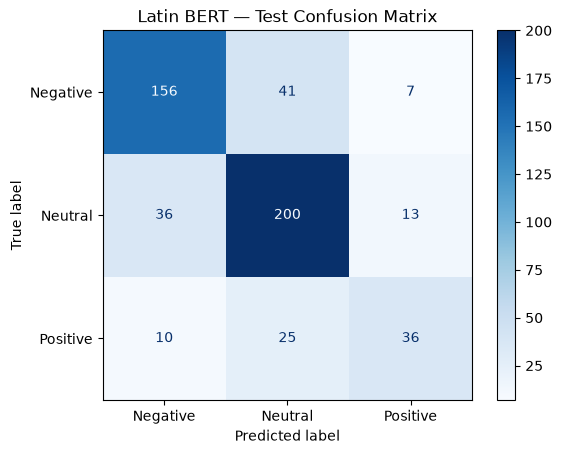

In [17]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on the held-out test set
predictions = trainer.predict(tokenized_dataset["test"])

y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=1)

labels = ["Negative", "Neutral", "Positive"]

# Per-class precision, recall, and F1
print("TEST CLASSIFICATION REPORT")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=labels,
        digits=3,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Latin BERT — Test Confusion Matrix")
plt.show()

In [18]:
from pathlib import Path

FINAL_MODEL_DIR = Path(
    "../../SentimentAnalysisLatin/models/latin_bert_authorial_v1/final"
)

trainer.save_model(str(FINAL_MODEL_DIR))
tokenizer.save_pretrained(str(FINAL_MODEL_DIR))

print("Saved model:", FINAL_MODEL_DIR.resolve())

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model: C:\Users\wills\dev\Trojan-Parse-Project\src\SentimentAnalysisLatin\models\latin_bert_authorial_v1\final


In [19]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_path = str(FINAL_MODEL_DIR.resolve())

inference_tokenizer = AutoTokenizer.from_pretrained(model_path)

inference_model = AutoModelForSequenceClassification.from_pretrained(
    model_path
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
inference_model.to(device)
inference_model.eval()

def predict_latin_sentiment(text):
    inputs = inference_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.inference_mode():
        logits = inference_model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)[0]

    predicted = probabilities.argmax().item()

    return {
        "sentiment": inference_model.config.id2label[predicted],
        "confidence": round(probabilities[predicted].item(), 4),
        "probabilities": {
            inference_model.config.id2label[i]: round(p.item(), 4)
            for i, p in enumerate(probabilities)
        }
    }

# Example from Seneca
text = (
    "Ita fac, mi Lucili; vindica te tibi, "
    "et tempus, quod adhuc aut auferebatur "
    "aut subripiebatur aut excidebat, collige et serva."
)

print(predict_latin_sentiment(text))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'sentiment': 'neutral', 'confidence': 0.7777, 'probabilities': {'negative': 0.0581, 'neutral': 0.7777, 'positive': 0.1642}}


In [22]:
import pandas as pd
import torch
from pathlib import Path

# Select 50 passages, balanced across the original labels
sample_sizes = {0: 17, 1: 17, 2: 16}

samples = pd.concat([
    test_df[test_df["label"] == label].sample(
        n=count,
        random_state=42
    )
    for label, count in sample_sizes.items()
])

samples = samples.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

samples.insert(
    0,
    "sample_id",
    [f"LAT-{i:03d}" for i in range(1, 51)]
)

# Run our trained Latin BERT model on all 50 passages
texts = samples["text"].tolist()

model_predictions = []
model_confidences = []

inference_model.eval()

for text in texts:
    inputs = inference_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.inference_mode():
        logits = inference_model(**inputs).logits
        probs = torch.softmax(logits, dim=-1)[0]

    predicted = probs.argmax().item()

    model_predictions.append(
        inference_model.config.id2label[predicted]
    )
    model_confidences.append(
        round(probs[predicted].item(), 4)
    )

# Build professor-facing CSV
professor_csv = samples[
    ["sample_id", "author", "work", "text"]
].copy()

professor_csv["model_sentiment"] = model_predictions
professor_csv["model_confidence"] = model_confidences

# Save
output_path = Path(
    "../../SentimentAnalysisLatin/data/evaluation"
)
output_path.mkdir(parents=True, exist_ok=True)

csv_path = output_path / "latin_bert_v1_professor_review_50.csv"

professor_csv.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"Saved {len(professor_csv)} passages to:")
print(csv_path.resolve())

print("\nModel prediction distribution:")
print(professor_csv["model_sentiment"].value_counts())

display(professor_csv.head())

Saved 50 passages to:
C:\Users\wills\dev\Trojan-Parse-Project\src\SentimentAnalysisLatin\data\evaluation\latin_bert_v1_professor_review_50.csv

Model prediction distribution:
model_sentiment
neutral     26
negative    20
positive     4
Name: count, dtype: int64


,sample_id,author,work,text,model_sentiment,model_confidence
0,LAT-001,Cicero,Letters to Atticus,ἐξ ἄστεως ἑπταλόφου στείχων παρέδωκεν μνῶν κδ′...,neutral,0.8296
1,LAT-002,Cicero,Letters to Friends,"his ego consiliis, si te praesentem habuissem,...",positive,0.9322
2,LAT-003,Cicero,Letters to Atticus,de Aebutio non credo nec tamen curo plus quam ...,neutral,0.9680
3,LAT-004,Caesar,De Bello Gallico,Omnes alacres et fiduciae pleni ad Alesiam pro...,neutral,0.8793
4,LAT-005,Cicero,Letters to Friends,"quod rogas, ut mea tibi scripta mittam, quae p...",neutral,0.8392


In [23]:
from huggingface_hub import login

login()

In [24]:
from huggingface_hub import HfApi
from pathlib import Path

api = HfApi()

username = api.whoami()["name"]
repo_id = f"{username}/latin-bert-authorial-sentiment-v1"

model_dir = Path(
    "../../SentimentAnalysisLatin/models/latin_bert_authorial_v1/final"
).resolve()

assert (model_dir / "config.json").exists(), "Model directory not found"

# Create the model repository
api.create_repo(
    repo_id=repo_id,
    repo_type="model",
    private=False,
    exist_ok=True
)

# Upload saved model and tokenizer
api.upload_folder(
    folder_path=str(model_dir),
    repo_id=repo_id,
    repo_type="model",
    commit_message="Upload Latin BERT authorial sentiment V1"
)

print(f"Uploaded: https://huggingface.co/{repo_id}")

'[WinError 10054] An existing connection was forcibly closed by the remote host' thrown while requesting POST https://huggingface.co/api/models/rtwins/latin-bert-authorial-sentiment-v1/commit/main
Retrying in 1s [Retry 1/5].


Uploaded: https://huggingface.co/rtwins/latin-bert-authorial-sentiment-v1
